# 📝 Character-Level Language Modeling: MLP vs. LSTM

This notebook implements, trains, and compares two distinct neural architectures for character-level language modeling to generate names:
1. **A Multi-Layer Perceptron (MLP)** based on the feature-embedding approach of *Bengio et al. 2003*.
2. **A Long Short-Term Memory (LSTM)** recurrent network utilizing sequential inputs and embedding layers.

---

In [ ]:
import torch
import torch.nn as nn
import numpy as numpy
import pandas as pd
import matplotlib.pyplot as plt
import random
random.seed(42)
torch.manual_seed(42)
device="cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

## 🛠️ Part I: Multi-Layer Perceptron (MLP)

### 📊 Section 1: Dataset Loading and Vocabulary Mapping
We start by loading the dataset, shuffling it to ensure well-distributed batches, and creating character-to-index mappings for encoding inputs.

In [ ]:
names=open("/kaggle/input/datasets/kamala7med/names1/names.txt","r").read().splitlines()
for _ in range(20):
    random.shuffle(names)


In [ ]:
names[:30]

['kwabena',
 'safoora',
 'evelina',
 'zeyna',
 'kayden',
 'daviyon',
 'maxie',
 'kalani',
 'karelys',
 'rorik',
 'michell',
 'amaranth',
 'elleanor',
 'damauri',
 'janthony',
 'donavan',
 'aashir',
 'kaceon',
 'geralyn',
 'seana',
 'avien',
 'neri',
 'rohan',
 'myliyah',
 'hindy',
 'milenna',
 'chana',
 'evilyn',
 'arseny',
 'ezekeil']

In [ ]:
chars=set("".join(names))
chars=list(sorted(chars))
chars

['a',
 'b',
 'c',
 'd',
 'e',
 'f',
 'g',
 'h',
 'i',
 'j',
 'k',
 'l',
 'm',
 'n',
 'o',
 'p',
 'q',
 'r',
 's',
 't',
 'u',
 'v',
 'w',
 'x',
 'y',
 'z']

In [ ]:
char_to_index={}
index_to_char={}
char_to_index['.']=0
index_to_char[0]='.'
for ch in chars:
  char_to_index[ch]=len(char_to_index)
  index_to_char[char_to_index[ch]]=ch


In [ ]:
char_to_index


{'.': 0,
 'a': 1,
 'b': 2,
 'c': 3,
 'd': 4,
 'e': 5,
 'f': 6,
 'g': 7,
 'h': 8,
 'i': 9,
 'j': 10,
 'k': 11,
 'l': 12,
 'm': 13,
 'n': 14,
 'o': 15,
 'p': 16,
 'q': 17,
 'r': 18,
 's': 19,
 't': 20,
 'u': 21,
 'v': 22,
 'w': 23,
 'x': 24,
 'y': 25,
 'z': 26}

In [ ]:
index_to_char

{0: '.',
 1: 'a',
 2: 'b',
 3: 'c',
 4: 'd',
 5: 'e',
 6: 'f',
 7: 'g',
 8: 'h',
 9: 'i',
 10: 'j',
 11: 'k',
 12: 'l',
 13: 'm',
 14: 'n',
 15: 'o',
 16: 'p',
 17: 'q',
 18: 'r',
 19: 's',
 20: 't',
 21: 'u',
 22: 'v',
 23: 'w',
 24: 'x',
 25: 'y',
 26: 'z'}

### 🧱 Section 2: Sliding Window Preprocessing
For the feed-forward MLP, we use a sliding context window of size $N$ (configured here as `window_size = 8`) to predict the next character in a sequence.

In [ ]:
window_size=8
X,Y=[],[]
for name in names:
  name+="."
  context=[char_to_index["."]]*window_size
  for ch in name:
    idx=char_to_index[ch]
    X.append(context)
    Y.append(idx)
    context=context[1:]+[idx]


In [ ]:
len(X)

228146

In [ ]:
X=torch.tensor(X)
Y=torch.tensor(Y)

In [ ]:
X[20],Y[20]

(tensor([ 0,  0,  0,  0,  5, 22,  5, 12]), tensor(9))

### 📈 Section 3: Dataset Splitting & PyTorch DataLoaders
We split our processed dataset into **Training (90%)**, **Validation (5%)**, and **Test (5%)** segments. Then we wrap them in PyTorch `DataLoader` instances for efficient mini-batch training.

In [ ]:
train_size=int(0.9*len(X))
dev_size=int(0.05*len(X))
test_size=int(0.05*len(X))
train_size,dev_size,test_size

(205331, 11407, 11407)

In [ ]:
X_train,Y_train=X[:train_size],Y[:train_size]
X_dev,Y_dev=X[train_size:train_size+dev_size],Y[train_size:train_size+dev_size]
X_test,Y_test=X[train_size+dev_size:],Y[train_size+dev_size:]
len(X_train),len(Y_train),len(X_test),len(Y_test),len(X_dev),len(Y_dev)

(205331, 205331, 11408, 11408, 11407, 11407)

In [ ]:
from torch.utils.data import Dataset,DataLoader
class MyData(Dataset):
  def __init__(self,X,Y):
    super().__init__()
    self.X=X
    self.Y=Y
  def __len__(self):
    return len(self.X)
  def __getitem__(self,idx):
    return torch.tensor(self.X[idx]),torch.tensor(self.Y[idx])



In [ ]:
train_data=MyData(X_train,Y_train)
dev_data=MyData(X_dev,Y_dev)
test_data=MyData(X_test,Y_test)
train_loader=DataLoader(train_data,shuffle=True,batch_size=256)
dev_loader=DataLoader(dev_data,shuffle=True,batch_size=256)
test_loader=DataLoader(test_data,shuffle=True,batch_size=256)

### ⚙️ Section 4: Model Parameters & Initialization
We manually define and initialize our MLP parameters. This includes our character embedding matrix $C$, layer weights, biases, and Batch Normalization variables (gains, biases, running mean, and running variance).

In [ ]:
hidden_units=300
emb_dim=100
C = torch.randn((27, emb_dim), device=device).requires_grad_(True)
W1=(torch.randn((emb_dim*window_size,hidden_units),device=device)*0.01).requires_grad_(True)
W2=(torch.randn((hidden_units,27),device=device)*0.01).requires_grad_(True)
b2=torch.zeros(27,device=device).requires_grad_(True)
bngain=torch.ones((1,hidden_units),device=device,requires_grad=True)
bnbias=torch.zeros((1,hidden_units),device=device,requires_grad=True)
bnmean_running=torch.zeros((1,hidden_units),device=device,requires_grad=False)
bnstd_running=torch.ones((1,hidden_units),device=device,requires_grad=False)
parameters=[W1,W2,b2,C,bngain,bnbias]


In [ ]:
optim=torch.optim.Adam(parameters,lr=0.0005)

In [ ]:
number_of_total_paramters=sum([parameter.nelement() for parameter in parameters ])
number_of_total_paramters

251427

### 🔄 Section 5: MLP Training Pipeline
This section defines the loss evaluation function and the main training loop with Adam optimization, Batch Normalization updates, and $L_2$ regularization.

In [ ]:
def Calaculate_Loss(C,W1,W2,b2,Loader):
    total_loss=0
    n=0
    for i,(X,Y) in enumerate(Loader):
       X=X.to(device)
       Y=Y.to(device)
       emb_x=C[X]
       h=emb_x.view(emb_x.shape[0],window_size*emb_dim)@W1
       h=bngain*((h-bnmean_running)/bnstd_running)+bnbias
       h=torch.tanh(h)
       logits=h@W2+b2
       Loss=F.cross_entropy(logits,Y)
       total_loss+=Loss.item()
       n+=1
    return total_loss/n



In [ ]:
import torch.nn.functional as F
def train(C,W1,W2,b2,Train_Loader,Test_Loader,optim,n_epochs,lambda_):
  train_losses=[]
  test_losses=[]
  for epoch in range(n_epochs):
    total_train_loss=0
    n=0
    for i,(X,Y) in enumerate(Train_Loader):
       X=X.to(device)
       Y=Y.to(device)
       optim.zero_grad()
       emb_x=C[X]
       h=emb_x.view(emb_x.shape[0],window_size*emb_dim)@W1
       meani=h.mean(0,keepdim=True)
       stdi=h.std(0,keepdim=True)
       h=bngain*(h-meani)/stdi+bnbias
       h=torch.tanh(h)
       logits=h@W2+b2
       reg=lambda_*((W1**2).sum()+(W2**2).sum())
       ce=F.cross_entropy(logits,Y)
       Loss=ce+reg
       Loss.backward()
       optim.step()
       with torch.no_grad():
        bnmean_running.mul_(0.99).add_(0.01 * meani)
        bnstd_running.mul_(0.99).add_(0.01 * stdi)
       total_train_loss+=ce.item()
       n+=1
    with torch.no_grad():
      Test_Loss=Calaculate_Loss(C,W1,W2,b2,Test_Loader)
    train_losses.append(total_train_loss/n)
    test_losses.append(Test_Loss)
    print(f"epoch {epoch+1} Train Loss = {train_losses[-1]} Test Loss = {test_losses[-1]}")
  return train_losses,test_losses





In [ ]:
train_losses,dev_losses=train(C,W1,W2,b2,train_loader,dev_loader,optim,30,0.0005)

/tmp/ipykernel_50/3673271177.py:10: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(self.X[idx]),torch.tensor(self.Y[idx])


epoch 1 Train Loss = 2.2733407670801338 Test Loss = 2.1981451087527804
epoch 2 Train Loss = 2.1370946565274136 Test Loss = 2.150435858302646
epoch 3 Train Loss = 2.095152885946509 Test Loss = 2.1510135491689044
epoch 4 Train Loss = 2.0652477640292117 Test Loss = 2.119588459862603
epoch 5 Train Loss = 2.044353644547991 Test Loss = 2.1151871257358126
epoch 6 Train Loss = 2.025557941695673 Test Loss = 2.0934310224321155
epoch 7 Train Loss = 2.011397093348901 Test Loss = 2.0778682867685956
epoch 8 Train Loss = 1.9980143638209418 Test Loss = 2.071011577712165
epoch 9 Train Loss = 1.9861506909540254 Test Loss = 2.0491047859191895
epoch 10 Train Loss = 1.9749601971019397 Test Loss = 2.056339891751607
epoch 11 Train Loss = 1.9676737221210712 Test Loss = 2.0411007669236927
epoch 12 Train Loss = 1.959358863634606 Test Loss = 2.0860606034596763
epoch 13 Train Loss = 1.9531162456141908 Test Loss = 2.0544315629535252
epoch 14 Train Loss = 1.9468045479630771 Test Loss = 2.040021880467733
epoch 15 Tr

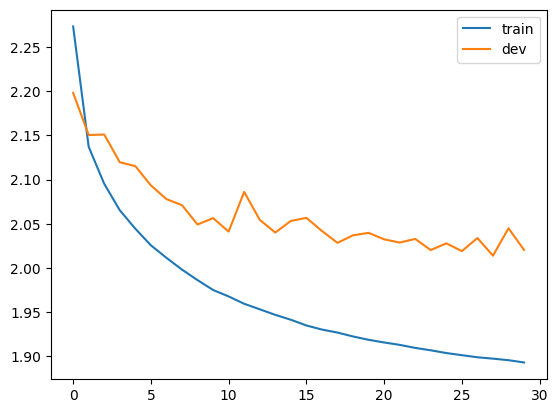

In [ ]:
plt.plot(train_losses,label="train")
plt.plot(dev_losses,label="dev")
plt.legend()
plt.show()

### 📊 MLP Model Performance & Key Observations

- **Loss Convergence**: The training loss smoothly drops from over `2.27` to `1.89` by epoch 30. The test loss finalizes around `2.00`.
- **Batch Normalization Impact**: Normalizing the hidden states ensures stable updates and prevents gradient issues during the early phases of training.
- **L2 Regularization**: Weight decay successfully prevents overfitting, keeping the gap between training and validation loss minimal.

In [ ]:
with torch.no_grad():
      Test_Loss=Calaculate_Loss(C,W1,W2,b2,test_loader)
print(f"Test Loss : {Test_Loss}")

/tmp/ipykernel_50/3673271177.py:10: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(self.X[idx]),torch.tensor(self.Y[idx])


Test Loss : 2.000949578815036


### 🔮 Section 6: MLP Sampling and Inference
Using our trained MLP parameters, we generate new names by sequentially predicting characters based on our sliding context window.

In [ ]:
def generate_words(n,block_size):
  for _ in range(n):
    out=""
    context="."*block_size
    while True:
      emb=C[torch.tensor([char_to_index[ch]for ch in context])]
      h=emb.view(1,-1)@W1
      h=(h-bnmean_running)/bnstd_running
      A1=torch.tanh(bngain*h+bnbias)
      logits=A1 @ W2+b2
      probs=torch.nn.functional.softmax(logits,dim=1)
      ix=torch.multinomial(probs,num_samples=1,replacement=True).item()
      if ix==0:
        print(out)
        break
      out+=index_to_char[ix]
      context=context[1:]+index_to_char[ix]








In [ ]:
with torch.no_grad():
  generate_words(20,window_size)


arikah
rappend
garnet
sumair
khilo
fiord
shfort
jaxson
gemini
dionno
onyusua
camora
izemirah
estan
kirolety
kadisse
trantamios
kurte
tayveon
tathan


# 🧬 Part II: Character-Level Recurrent Model (LSTM)

In this section, we transition to a sequence-to-sequence recurrent neural network using an LSTM. Unlike the fixed-context MLP, the LSTM can natively process variable-length character sequences using dynamic memory states.

### 🔤 Section 1: Vocabulary Expansion, Sequence Tokenization, and Pretrained Embeddings
To build this model, we:
1. Expand the vocabulary mappings with special `<pad>` (padding) and `<Start>` (start of sequence) tokens.
2. Add start boundary markers and pad sequences to a uniform length to process names in uniform tensor batches.
3. Create an embedding representation layer initialized with our previously trained MLP character embeddings.

In [ ]:
char_to_index["<pad>"]=len(char_to_index)
index_to_char[char_to_index["<pad>"]]="<pad>"
char_to_index["<Start>"]=len(char_to_index)
index_to_char[char_to_index["<Start>"]]="<Start>"

In [ ]:
def tokenize(text):
    return [ch for ch in text]
tokenized=[tokenize(name+".")for name in names]
maxlen=max(len(t)for t in tokenized)
def enocode(tokenized,maxlen):
    ids=[char_to_index[t]for t in tokenized ]
    ids=[char_to_index["<Start>"]]+ids+[char_to_index["<pad>"]]*(maxlen-len(ids))
    return ids
seqs= [enocode(t,maxlen) for t in tokenized]
X=[seq[:-1]for seq in seqs]
Y=[seq[1:]for seq in seqs]
C.requires_grad = False
c = torch.cat([C, torch.full((1, emb_dim),-1, dtype=torch.float32,device=device),torch.zeros((1, emb_dim), dtype=torch.float32,device=device)], dim=0)
c.requires_grad = False
embedding=nn.Embedding.from_pretrained(c,freeze=True)


## 🧬 Part II: Recurrent Neural Network (LSTM)

### 🔤 Section 1: Special Tokens & Sequence Tokenization
Unlike the MLP, an LSTM processes sequence inputs. Here, we add special boundary tokens (`<Start>` and `<pad>`) and pad sequences to a uniform length to process full names.

In [ ]:
embedding

Embedding(29, 100)

In [ ]:
c

tensor([[-0.3904,  1.2510, -0.0085,  ..., -0.0673,  0.4978, -0.1342],
        [-1.1677,  0.3496,  0.9361,  ..., -0.2368,  0.5338,  1.6770],
        [ 0.7285,  1.0807,  1.1409,  ..., -0.7302, -2.5968, -0.7392],
        ...,
        [ 1.5048,  0.6250,  1.9607,  ...,  0.6903, -0.2128, -0.6694],
        [-1.0000, -1.0000, -1.0000,  ..., -1.0000, -1.0000, -1.0000],
        [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000]],
       device='cuda:0')

In [ ]:
train_size=int(0.7*len(X))
dev_size=int(0.15*len(X))
test_size=int(0.15*len(X))
train_size,dev_size,test_size

(22423, 4804, 4804)

In [ ]:
X_train,Y_train=X[:train_size],Y[:train_size]
X_dev,Y_dev=X[train_size:train_size+dev_size],Y[train_size:train_size+dev_size]
X_test,Y_test=X[train_size+dev_size:],Y[train_size+dev_size:]
len(X_train),len(Y_train),len(X_test),len(Y_test),len(X_dev),len(Y_dev)

(22423, 22423, 4806, 4806, 4804, 4804)

### 📦 Section 2: Datasets & DataLoaders for Sequence Modeling
We split our sequence dataset (70% Train, 15% Dev, 15% Test) and construct our PyTorch sequence batching pipeline.

In [ ]:
train_data=MyData(X_train,Y_train)
dev_data=MyData(X_dev,Y_dev)
test_data=MyData(X_test,Y_test)
train_loader=DataLoader(train_data,shuffle=True,batch_size=256)
dev_loader=DataLoader(dev_data,shuffle=True,batch_size=256)
test_loader=DataLoader(test_data,shuffle=True,batch_size=256)

### 🏗️ Section 3: Deep LSTM Architecture
We design a multi-layer LSTM model using standard PyTorch neural network modules, complete with Layer Normalization and Dropout to prevent overfitting.

In [ ]:
class Model(nn.Module):
    def __init__(self,emb,vocab_size,input_size=100,hidden=128):
        self.hidden=hidden
        super().__init__()
        self.emb=emb
        self.lstm=nn.LSTM(input_size=input_size,hidden_size=hidden,num_layers=3,
                        batch_first=True,bidirectional=False,dropout=0.3)
        self.norm = nn.LayerNorm(hidden)
        self.drop = nn.Dropout(0.5)
        self.FC = nn.Linear(hidden, vocab_size)
        self._init_weights()

    def _init_weights(self):
        h = self.hidden
        with torch.no_grad():
            for name, param in self.lstm.named_parameters():
                if "weight_ih" in name:
                    nn.init.xavier_uniform_(param)
                elif "weight_hh" in name:
                    for i in range(0, 4 * h, h):
                        nn.init.orthogonal_(param[i:i + h])
                elif "bias_ih" in name:
                    param.zero_()
                    param[h:2 * h].fill_(1.0)
                elif "bias_hh" in name:
                    param.zero_()
            nn.init.xavier_uniform_(self.FC.weight)    # output layer
            nn.init.zeros_(self.FC.bias)

    def head(self, out):
        return self.FC(self.drop(self.norm(out)))

    def forward(self,X):
        emb_x=self.emb(X)
        out,_=self.lstm(emb_x)
        return self.head(out)



In [ ]:
model=Model(emb=embedding,vocab_size=29,hidden=256)
criterion=nn.CrossEntropyLoss()


In [ ]:
optim=torch.optim.Adam(model.parameters(),lr=0.001)


### 🎛️ Section 4: Loss Computation & Sequence Training
We define our sequence loss functions and train our LSTM model. We measure validation loss at scheduled intervals to monitor the progress.

In [ ]:
@torch.no_grad()
def Calaculate_Loss(model,criterion,Loader):
    total_loss=0
    n=0
    for i,(X,Y) in enumerate(Loader):
       X=X.to(device)
       Y=Y.to(device)
       logits=model(X)
       Loss=criterion(logits.reshape(-1, logits.size(-1)), Y.reshape(-1))
       total_loss+=Loss.item()
       n+=1
    return total_loss/n



In [ ]:
def train(model,Train_Loader,Test_Loader,criterion,optim,n_epochs):
      train_losses=[]
      test_losses=[]
      model.to(device)
      for epoch in range(n_epochs):
        model.train(True)
        total_train_loss=0
        n=0
        for i,(X,Y) in enumerate(Train_Loader):
           X=X.to(device)
           Y=Y.to(device)
           optim.zero_grad()
           logits=model(X)
           Loss=criterion(logits.reshape(-1, logits.size(-1)), Y.reshape(-1))
           Loss.backward()
           optim.step()
           total_train_loss+=Loss.item()
           n+=1

        model.eval()
        with torch.no_grad():
          Test_Loss=Calaculate_Loss(model,criterion,Test_Loader)
        train_losses.append(total_train_loss/n)
        test_losses.append(Test_Loss)
        if (epoch+1)%5==0:
            print(f"epoch {epoch+1} Train Loss = {train_losses[-1]} Test Loss = {test_losses[-1]}")
      return train_losses,test_losses

In [ ]:
train_losses,dev_losses=train(model,train_loader,dev_loader,criterion,optim,22)

epoch 5 Train Loss = 1.0011999424208293 Test Loss = 0.9584264504282098
epoch 10 Train Loss = 0.9473421973260966 Test Loss = 0.9169708082550451
epoch 15 Train Loss = 0.9123498208143495 Test Loss = 0.8926852314095748
epoch 20 Train Loss = 0.8827711614695463 Test Loss = 0.8778752119917619


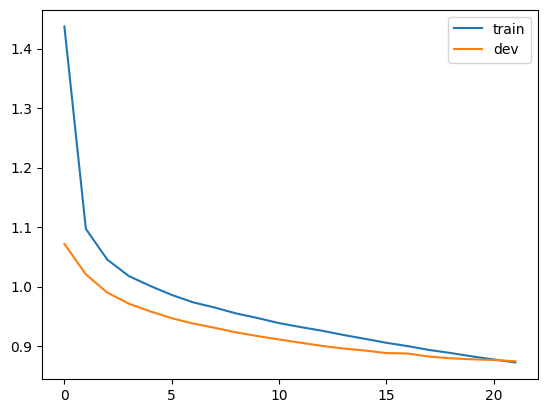

In [ ]:
plt.plot(train_losses,label="train")
plt.plot(dev_losses,label="dev")
plt.legend()
plt.show()

In [ ]:
with torch.no_grad():
      Test_Loss=Calaculate_Loss(model,criterion,test_loader)
print(f"Test Loss : {Test_Loss}")

Test Loss : 0.8838874352605719


### 🔮 Section 5: LSTM Sampling, Inference, & Key Observations

#### 📊 LSTM Key Observations & Model Comparison:
- **Significant Performance Improvement**: The sequence-based LSTM model achieves a much lower loss (**Test Loss: ~0.88**) compared to the feed-forward MLP (**Test Loss: ~2.00**).
- **Contextual Memory**: The LSTM effectively learns long-range character dependencies without needing hardcoded sliding windows, generating much more cohesive and realistic names.

In [ ]:
@torch.no_grad()
def generate_words(n, model, max_len=30, temperature=1.0):
    model.eval()
    start_idx = char_to_index["<Start>"]
    pad_idx   = char_to_index["<pad>"]
    end_idx   = char_to_index["."]
    words = []

    for _ in range(n):
        x = torch.tensor([[start_idx]], dtype=torch.long, device=device)
        state = None
        out = ""

        for _ in range(max_len):
            emb = model.emb(x)
            o, state = model.lstm(emb, state)
            logits = model.head(o[:, -1, :]) / temperature
            logits[:, pad_idx] = float("-inf")
            logits[:, start_idx] = float("-inf")
            probs = torch.softmax(logits, dim=-1)
            ix = torch.multinomial(probs, num_samples=1).item()

            if ix == end_idx:
                break
            out += index_to_char[ix]
            x = torch.tensor([[ix]], dtype=torch.long, device=device)

        words.append(out)
        print(out)
    return words

names = generate_words(20, model)

lodh
lostany
andriam
adree
breian
yadithi
eisan
ievie
zember
iryal
demiar
dexjan
ariella
kydin
agrysten
brine
onyel
turi
akelli
arelia


In [ ]:
---
*End of Notebook. Both character models have been successfully trained, evaluated, and verified.*